In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.ExperimentSet import ExperimentSet
from src.Retrieval import Retrieval

In [3]:
EXPERIMENT_SET = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08'
V08 = ExperimentSet(EXPERIMENT_SET)
V08.set_retrieval_list()
V08.load_retrievals(iteration=-1)

In [4]:
ref_key = Path('/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/default')
compare0 = V08.compare_to(ref_key, 0.67, 'cloud', extinction_th=0.0, tau_th=0.0)
compare1 = V08.compare_to(ref_key, 0.67, 'cloud', extinction_th=0.3, tau_th=0.3)
stats0 = V08.table_cloud_stats(0.67, 'cloud', extinction_th=0.0, tau_th=0.0)
stats1 = V08.table_cloud_stats(0.67, 'cloud', extinction_th=0.3, tau_th=0.3)
df0 = pd.merge(compare0, stats0, on='retrieval')
df1 = pd.merge(compare1, stats1, on='retrieval')

In [5]:
r = Retrieval(PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default')
r.load_retrieval()

In [7]:
ext_ths = np.linspace(0, 1, 21)
tau_ths = np.linspace(0, 1, 21)
volume = np.zeros((len(ext_ths), len(tau_ths)))
tau_bar = np.zeros((len(ext_ths), len(tau_ths)))
cf = np.zeros((len(ext_ths), len(tau_ths)))

for i, eth in enumerate(ext_ths):
    for j, tth in enumerate(tau_ths):
        N, volume[i,j], tau_bar[i,j], cf[i,j] = r.get_cloud_volume_stats(0.67, 'cloud', extinction_th=eth, tau_th=tth)

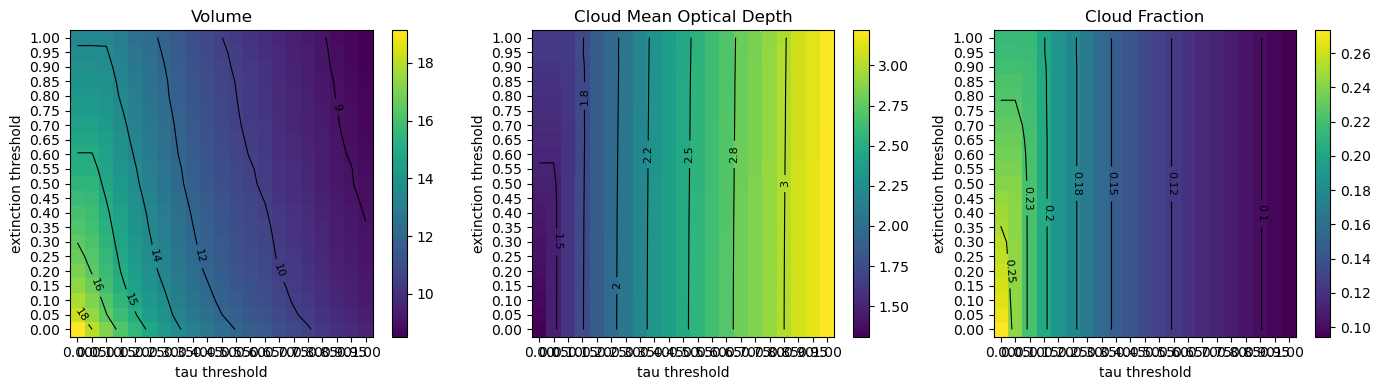

In [8]:
f, ax = plt.subplots(1, 3, figsize=(14,4))

# create coordinate grid matching array shape
X, Y = np.meshgrid(tau_ths, ext_ths)

titles = ['Volume', 'Cloud Mean Optical Depth', 'Cloud Fraction']
for i, data in enumerate([volume, tau_bar, cf]):
    # color background using pcolormesh (numeric axes)
    im = ax[i].pcolormesh(X, Y, data, shading='auto', cmap='viridis')
    # add contour lines on top
    cs = ax[i].contour(X, Y, data, colors='k', linewidths=0.8)
    ax[i].clabel(cs, inline=True, fontsize=8, fmt='%.2g')
    ax[i].set_title(titles[i])
    ax[i].set_xlabel('tau threshold')
    ax[i].set_ylabel('extinction threshold')
    ax[i].set_xticks(tau_ths)
    ax[i].set_yticks(ext_ths)
    plt.colorbar(im, ax=ax[i])

plt.tight_layout()
